# Анализ ДТП — участник №3
**Датасет:** STATS19 Collisions. **Цель:** проверить три гипотезы и выполнить регрессионный анализ.

Используются Pandas, NumPy, Matplotlib и Scikit-learn, а также встроенные модули Python. Исходный CSV не изменяется. Предполагается одна строка на ДТП: ETL должен обеспечить уникальность `collision_index`.

- H1: доля тяжёлых и смертельных ДТП на дорогах с лимитом 50–70 mph выше, чем с лимитом 20–30 mph.
- H2: доля тяжёлых и смертельных ДТП в темноте без уличного освещения выше, чем при дневном свете.
- H3: в часы пик (07–10 и 16–19) зарегистрировано больше ДТП за час, чем в остальные часы.

Нулевые гипотезы: соответствующие доли/средние равны (для направленного теста нулевая область также включает отсутствие увеличения). Уровень значимости 0,05. Источник кодов: https://www.gov.uk/government/statistical-data-sets/road-safety-open-data .

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from pathlib import Path
from math import erfc, sqrt

FILE = Path('dft-road-casualty-statistics-collision-1979-latest-published-year.csv')
START_YEAR = 2022
END_YEAR = 2024
CHUNK_SIZE = 100_000
ALPHA = 0.05
RESULTS = Path('results')
RESULTS.mkdir(exist_ok=True)

if not FILE.exists():
    raise FileNotFoundError(f'Поместите CSV рядом с ноутбуком: {FILE.resolve()}')

## 1. Загрузка данных и контроль качества
Читаем только нужные столбцы блоками. Считаем годовую статистику по всему CSV. Для гипотез сохраняем только 2022–2024 гг. — это уменьшает расход памяти и ограничивает смешивание разных исторических периодов. Даже в этом периоде остаются различия в учёте тяжести. Проверяем идентификаторы в выбранном периоде; общая годовая статистика предполагает, что ETL уже удалил дубликаты. Неизвестные значения исключаются только из соответствующих расчётов.

In [2]:
columns = ['collision_index', 'collision_year', 'collision_severity',
           'speed_limit', 'light_conditions', 'date', 'time', 'police_force']
parts = []
annual_parts = []
rows = 0

for chunk in pd.read_csv(FILE, usecols=columns, chunksize=CHUNK_SIZE,
                         dtype={'collision_index': 'string', 'date': 'string', 'time': 'string'}):
    rows += len(chunk)
    chunk['collision_year'] = pd.to_numeric(chunk['collision_year'], errors='coerce')
    annual_parts.append(chunk['collision_year'].value_counts())
    selected = chunk[chunk['collision_year'].between(START_YEAR, END_YEAR)].copy()
    if not selected.empty:
        parts.append(selected)

annual = (pd.concat(annual_parts).groupby(level=0).sum().sort_index()
          .rename('collision_count').rename_axis('year').reset_index())
annual.to_csv(RESULTS / 'annual.csv', index=False)
if not parts:
    raise ValueError('В файле нет записей за выбранный период.')
df = pd.concat(parts, ignore_index=True)
del parts, annual_parts

if df['collision_index'].isna().any() or df['collision_index'].str.strip().eq('').any():
    raise ValueError('Есть пустые идентификаторы ДТП. Верните данные на ETL.')
if df['collision_index'].duplicated().any():
    raise ValueError('Есть повторяющиеся идентификаторы ДТП. Удалите дубликаты на ETL.')

for col in ['collision_severity', 'speed_limit', 'light_conditions', 'police_force']:
    df[col] = pd.to_numeric(df[col], errors='coerce')
df['severe'] = np.where(df['collision_severity'].isin([1, 2]), 1,
                       np.where(df['collision_severity'].eq(3), 0, np.nan))
df['date'] = pd.to_datetime(df['date'], format='%d/%m/%Y', errors='coerce')
valid_time = df['time'].str.fullmatch(r'(?:[01]\d|2[0-3]):[0-5]\d').fillna(False)
df['hour'] = pd.to_numeric(df['time'].where(valid_time).str[:2], errors='coerce')
valid_date = df['date'].dt.year.eq(df['collision_year'])
df['date'] = df['date'].where(valid_date)

quality = pd.DataFrame({'metric': ['rows_in_file', 'rows_in_period', 'unknown_severity',
                                   'unknown_or_other_speed', 'unknown_or_other_light', 'invalid_date_or_time'],
                        'value': [rows, len(df), df['severe'].isna().sum(),
                                  (~df['speed_limit'].isin([20,30,40,50,60,70])).sum(),
                                  (~df['light_conditions'].isin([1,4,5,6,7])).sum(),
                                  (df['date'].isna() | df['hour'].isna()).sum()]})
print(quality.to_string(index=False))
quality.to_csv(RESULTS / 'quality.csv', index=False)

                metric   value
          rows_in_file 9116625
        rows_in_period  311189
      unknown_severity       0
unknown_or_other_speed       3
unknown_or_other_light       7
  invalid_date_or_time       0


## 2. Проверка H1 и H2 — сравнение двух долей
Используем односторонний Z-тест двух пропорций. Доля = число тяжёлых/смертельных ДТП / число ДТП с известной тяжестью в группе. Z-статистика рассчитывается по объединённой доле. `erfc` — встроенная математическая функция Python для получения p-value нормального распределения; новая сторонняя библиотека не требуется. Если в группах слишком мало наблюдений, тест останавливается. Разницу выводим в процентных пунктах.

In [3]:
def compare_shares(data, mask1, mask0, name, label1, label0):
    a = data.loc[mask1, 'severe'].dropna()
    b = data.loc[mask0, 'severe'].dropna()
    n1, n0 = len(a), len(b)
    if min(n1, n0) == 0:
        raise ValueError(f'{name}: одна из групп пуста')
    x1, x0 = int(a.sum()), int(b.sum())
    if min(x1, n1-x1, x0, n0-x0) < 5:
        raise ValueError(f'{name}: слишком мало наблюдений для Z-теста')
    p1, p0 = x1/n1, x0/n0
    pooled = (x1+x0)/(n1+n0)
    se = np.sqrt(pooled*(1-pooled)*(1/n1+1/n0))
    z = (p1-p0)/se
    p_value = 0.5 * erfc(z/sqrt(2))
    table = pd.DataFrame({'group': [label1, label0], 'total': [n1,n0],
                          'severe_count': [x1,x0], 'severe_percent': [100*p1,100*p0]})
    result = {'hypothesis': name, 'group1': label1, 'group0': label0,
              'value1': 100*p1, 'value0': 100*p0, 'difference': 100*(p1-p0),
              'unit': 'percentage points', 'z': z, 'p_value': p_value}
    return table, result

speed_table, h1 = compare_shares(df, df['speed_limit'].isin([50,60,70]),
                                df['speed_limit'].isin([20,30]), 'H1', '50–70 mph', '20–30 mph')
print(speed_table.to_string(index=False))
speed_table.to_csv(RESULTS / 'speed.csv', index=False)

light_table, h2 = compare_shares(df, df['light_conditions'].eq(6),
                                df['light_conditions'].eq(1), 'H2', 'Без освещения', 'Дневной свет')
print(light_table.to_string(index=False))
light_table.to_csv(RESULTS / 'light.csv', index=False)

    group  total  severe_count  severe_percent
50–70 mph  68883         21176       30.741983
20–30 mph 215038         46723       21.727788
        group  total  severe_count  severe_percent
Без освещения  16878          5854       34.684204
 Дневной свет 221752         51177       23.078484


## 3. Проверка H3 — часы пик
Для каждого календарного дня считаем ДТП за час в двух периодах (6 часов пик, 18 остальных). Сравниваем парные разности по дням. Используем нормальное приближение для среднего парных разностей (не точный t-тест); оно требует достаточно дней и приблизительной независимости разностей. Временная зависимость может влиять на p-value. Все дни должны присутствовать в выборке с корректным временем, иначе тест не выполняется: нельзя считать отсутствующие данные нулём. Период включает будни и выходные.

In [4]:
timed = df.dropna(subset=['date', 'hour']).copy()
timed['hour'] = timed['hour'].astype(int)
timed['peak'] = timed['hour'].isin([7,8,9,16,17,18])
calendar = pd.date_range(f'{START_YEAR}-01-01', f'{END_YEAR}-12-31', freq='D')
if len(calendar.difference(timed['date'].unique())):
    raise ValueError('Не все дни периода представлены корректными датами/временем. Проверьте полноту данных или выберите полные годы.')

daily = (timed.groupby(['date','peak']).size().unstack(fill_value=0)
         .reindex(index=calendar, columns=[True,False], fill_value=0))
daily.columns = ['peak_count', 'other_count']
daily.index.name = 'date'
daily['peak_per_hour'] = daily['peak_count']/6
daily['other_per_hour'] = daily['other_count']/18
daily['difference'] = daily['peak_per_hour']-daily['other_per_hour']
d = daily['difference']
if len(d) < 30 or d.std(ddof=1) == 0:
    raise ValueError('Недостаточно вариации или дней для нормального приближения.')
z3 = d.mean()/(d.std(ddof=1)/np.sqrt(len(d)))
h3 = {'hypothesis': 'H3', 'group1': 'Часы пик', 'group0': 'Другие часы',
      'value1': daily['peak_per_hour'].mean(), 'value0': daily['other_per_hour'].mean(),
      'difference': d.mean(), 'unit': 'collisions/hour', 'z': z3,
      'p_value': 0.5*erfc(z3/sqrt(2))}
print(daily[['peak_per_hour','other_per_hour']].mean())
daily.to_csv(RESULTS / 'daily.csv')
hourly = timed.groupby('hour').size().reindex(range(24), fill_value=0).rename('collision_count')
hourly.to_csv(RESULTS / 'hourly.csv')
heatmap = (timed.groupby([timed['date'].dt.dayofweek.rename('weekday'), 'hour']).size()
           .unstack(fill_value=0).reindex(index=range(7), columns=range(24), fill_value=0))
heatmap.to_csv(RESULTS / 'heatmap.csv')

peak_per_hour     18.405414
other_per_hour     9.638838
dtype: float64


## 4. Итоги статистических тестов
Поправка Бонферрони для трёх проверок: умножаем p-value на 3 (не более 1). Если скорректированное p-value < 0,05 — отклоняем H0 в пользу направленной H1. Иначе недостаточно оснований отклонить H0. Учитывайте величину разницы, а не только значимость. Тесты являются приближёнными; пространственная и временная зависимость наблюдений может завышать значимость.

In [5]:
hypotheses = pd.DataFrame([h1,h2,h3])
hypotheses['p_adjusted'] = np.minimum(hypotheses['p_value']*len(hypotheses), 1)
hypotheses['decision'] = np.where(hypotheses['p_adjusted'] < ALPHA,
                                  'Отклоняем H0', 'Недостаточно оснований отклонить H0')
print(hypotheses.to_string(index=False))
hypotheses.to_csv(RESULTS / 'hypotheses.csv', index=False)

hypothesis        group1       group0    value1    value0  difference              unit         z       p_value    p_adjusted     decision
        H1     50–70 mph    20–30 mph 30.741983 21.727788    9.014195 percentage points 48.267929  0.000000e+00  0.000000e+00 Отклоняем H0
        H2 Без освещения Дневной свет 34.684204 23.078484   11.605720 percentage points 34.081340 6.971175e-255 2.091352e-254 Отклоняем H0
        H3      Часы пик  Другие часы 18.405414  9.638838    8.766575   collisions/hour 49.044365  0.000000e+00  0.000000e+00 Отклоняем H0


## 5. Логистическая регрессия (Scikit-learn)
Целевая переменная — тяжёлое/смертельное ДТП (1) либо лёгкое (0). Сравниваем те же группы скорости и света; дополнительно учитываем год и полицейское подразделение. Оставляем только наблюдения с известными значениями всех признаков. `exp(коэффициент)` — отношение шансов при прочих включённых признаках, а не изменение вероятности и не причинный эффект. Модель с обычной L2-регуляризацией используется для описания связи, не для статистических p-value и не для оценки прогнозной точности.

In [6]:
model_data = df[df['speed_limit'].isin([20,30,50,60,70]) &
                df['light_conditions'].isin([1,6]) & df['severe'].notna() &
                df['police_force'].gt(0)].copy()
model_data['high_speed'] = model_data['speed_limit'].isin([50,60,70]).astype(int)
model_data['no_lighting'] = model_data['light_conditions'].eq(6).astype(int)
X = pd.get_dummies(model_data[['high_speed','no_lighting','collision_year','police_force']],
                   columns=['collision_year','police_force'], drop_first=True, dtype=int)
y = model_data['severe'].astype(int)
if y.nunique() != 2 or X['high_speed'].nunique() != 2 or X['no_lighting'].nunique() != 2:
    raise ValueError('Недостаточно различных наблюдений для регрессии.')
model = LogisticRegression(max_iter=1000)
model.fit(X,y)
regression = pd.DataFrame({'feature': X.columns, 'coefficient': model.coef_[0],
                           'odds_ratio': np.exp(model.coef_[0])})
regression.to_csv(RESULTS / 'regression.csv', index=False)
print('Количество наблюдений:', len(y))
print(regression.head(2).to_string(index=False))

Количество наблюдений: 217794
    feature  coefficient  odds_ratio
 high_speed     0.384391    1.468720
no_lighting     0.264145    1.302316


## 6. Графики для участника №4
Четыре графика по гипотезам и один исторический. В дашборд передаются CSV-таблицы. Временная статистика не является риском ДТП на одну поездку: нет данных об интенсивности движения.

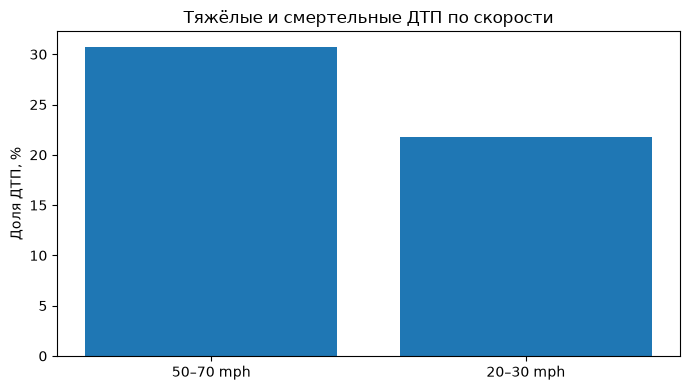

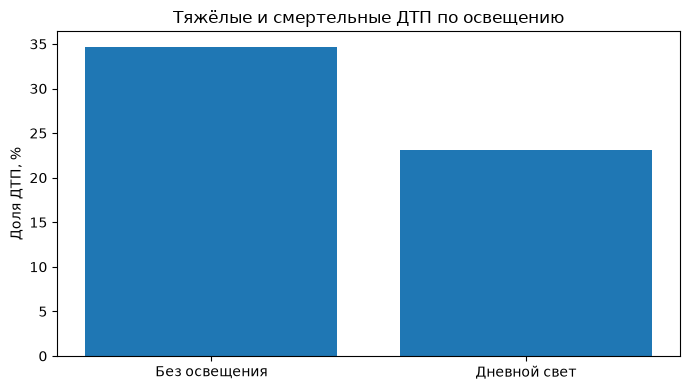

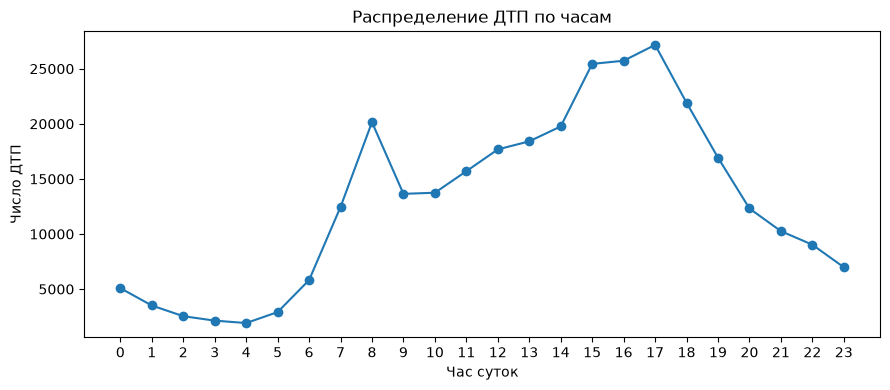

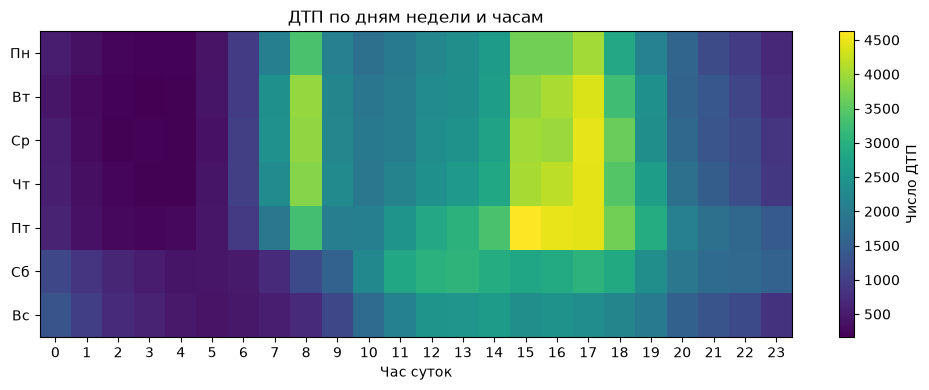

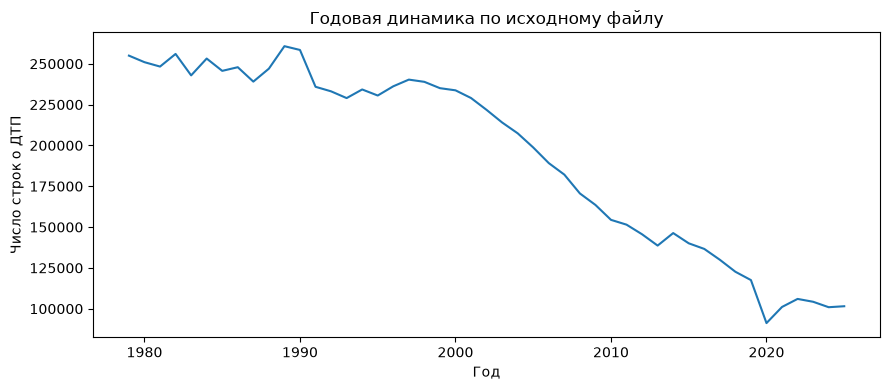

Результаты сохранены: C:\Users\user\PycharmProjects\PythonProject\Архитектура больших данных\results


In [7]:
def save_plot(filename):
    plt.tight_layout()
    plt.savefig(RESULTS / filename, dpi=150)
    plt.show()
    plt.close()

for table, name, title in [(speed_table, 'speed.png', 'Тяжёлые и смертельные ДТП по скорости'),
                           (light_table, 'light.png', 'Тяжёлые и смертельные ДТП по освещению')]:
    plt.figure(figsize=(7,4))
    plt.bar(table['group'], table['severe_percent'])
    plt.ylabel('Доля ДТП, %')
    plt.title(title)
    save_plot(name)

plt.figure(figsize=(9,4))
plt.plot(hourly.index, hourly.values, marker='o')
plt.xticks(range(24))
plt.xlabel('Час суток')
plt.ylabel('Число ДТП')
plt.title('Распределение ДТП по часам')
save_plot('hourly.png')

plt.figure(figsize=(10,4))
plt.imshow(heatmap.values, aspect='auto')
plt.yticks(range(7), ['Пн','Вт','Ср','Чт','Пт','Сб','Вс'])
plt.xticks(range(24))
plt.xlabel('Час суток')
plt.colorbar(label='Число ДТП')
plt.title('ДТП по дням недели и часам')
save_plot('heatmap.png')

plt.figure(figsize=(9,4))
plt.plot(annual['year'], annual['collision_count'])
plt.xlabel('Год')
plt.ylabel('Число строк о ДТП')
plt.title('Годовая динамика по исходному файлу')
save_plot('annual.png')
print('Результаты сохранены:', RESULTS.resolve())

## 7. Выводы
После запуска используйте `hypotheses.csv` для формулировки выводов: сравните значения групп, разницу, скорректированное p-value и направление эффекта. Не пишите о подтверждённых причинных связях. STATS19 учитывает зарегистрированные полицией ДТП с пострадавшими на дорогах общего пользования; изменения полноты и методики регистрации ограничивают исторические сравнения. Ограничение скорости не является фактической скоростью автомобиля. Реальные результаты будут получены только после запуска на полном CSV.